In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from pandas.plotting import scatter_matrix
Sleep=pd.read_csv('../data/sleep_health_dataset.csv', header=0, sep=',')
#Sleep.head()
#Sleep.tail()
#Sleep.shape
#Sleep.info()
#Sleep.columns
#Sleep['country'].unique()
#Sleep['occupation'].unique()
#Sleep['chronotype'].unique()
#Sleep['mental_health_condition'].unique()
#Sleep['season'].unique()
#Sleep['day_type'].unique()
#Sleep['gender'].unique()
#Sleep['sleep_disorder_risk'].unique()
#Sleep['sleep_disorder_risk'].value_counts()
#Sleep['chronotype'].value_counts()
#Sleep[Sleep['sleep_disorder_risk']=='Severe']
#Sleep['sleep_quality_score'][Sleep['chronotype']=='Evening']
#Sleep.describe()
#Sleep.hist(bins=50, figsize=(20,15))
#plt.show()
train_set,test_set=train_test_split(Sleep,test_size=0.2,random_state=42)
train_set.shape
train_set.head()

,person_id,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,...,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,season,day_type,cognitive_performance_score,sleep_disorder_risk,felt_rested
75220,75221,23,Female,Lawyer,27.2,Japan,8.68,4.7,22.0,29.9,...,62,1,0,24.1,1.06,Autumn,Weekend,64.5,Mild,1
48955,48956,30,Female,Driver,18.6,Japan,3.84,3.2,20.2,24.4,...,64,0,0,15.0,3.00,Winter,Weekday,43.2,Mild,0
44966,44967,33,Male,Software Engineer,31.0,USA,5.76,4.0,17.6,20.9,...,75,0,0,24.9,2.69,Winter,Weekend,45.5,Mild,0
13568,13569,56,Male,Student,24.4,South Korea,5.92,4.7,21.5,20.6,...,66,1,0,18.7,1.15,Winter,Weekday,56.0,Healthy,0
92727,92728,25,Male,Teacher,25.0,USA,5.93,2.7,19.8,21.2,...,67,0,0,18.5,1.39,Winter,Weekday,50.6,Mild,0


Text(0.5, 1.0, 'Sleep Quality Analysis')

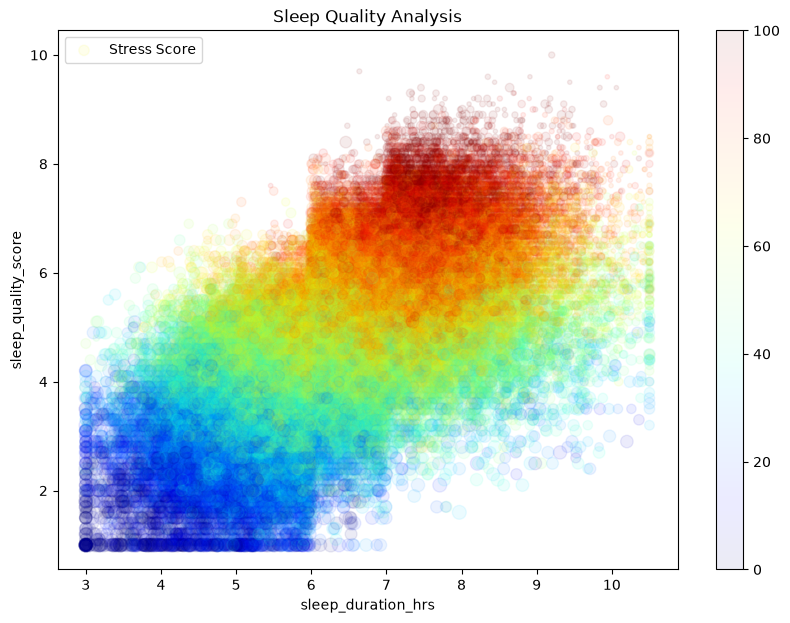

In [20]:
data=train_set.copy()
data.head()

data.plot(
    kind="scatter",
    x="sleep_duration_hrs",
    y="sleep_quality_score",
    s=data["stress_score"] * 10,
    label="Stress Score",
    c=data["cognitive_performance_score"],
    cmap=plt.get_cmap("jet"),
    figsize=(10, 7),
    alpha=0.08
)
plt.title("Sleep Quality Analysis")


<Axes: xlabel='sleep_duration_hrs', ylabel='sleep_quality_score'>

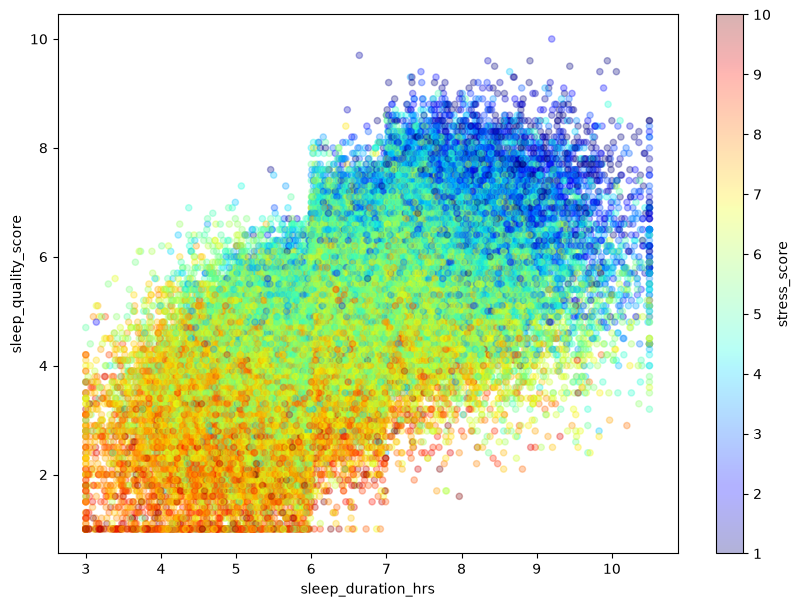

In [21]:
data = train_set.copy()

data.plot(
    kind="scatter",
    x="sleep_duration_hrs",
    y="sleep_quality_score",
    c="stress_score",
    cmap=plt.get_cmap("jet"),
    colorbar=True,
    figsize=(10, 7),
    alpha=0.3
)

In [26]:
#standard correlation coefficient
corr_matrix=data.corr(numeric_only=True)
corr_matrix["sleep_quality_score"].sort_values(ascending=False)

sleep_quality_score            1.000000
cognitive_performance_score    0.860198
sleep_duration_hrs             0.646306
felt_rested                    0.477365
rem_percentage                 0.255544
deep_sleep_percentage          0.093855
sleep_aid_used                 0.048131
exercise_day                   0.023297
steps_that_day                 0.015689
person_id                      0.000943
weekend_sleep_diff_hrs        -0.003909
nap_duration_mins             -0.019865
room_temperature_celsius      -0.022037
age                           -0.026947
caffeine_mg_before_bed        -0.050719
bmi                           -0.058298
heart_rate_resting_bpm        -0.067729
screen_time_before_bed_mins   -0.081081
alcohol_units_before_bed      -0.081771
shift_work                    -0.264086
sleep_latency_mins            -0.290722
work_hours_that_day           -0.365572
wake_episodes_per_night       -0.381055
stress_score                  -0.638109
Name: sleep_quality_score, dtype: float6

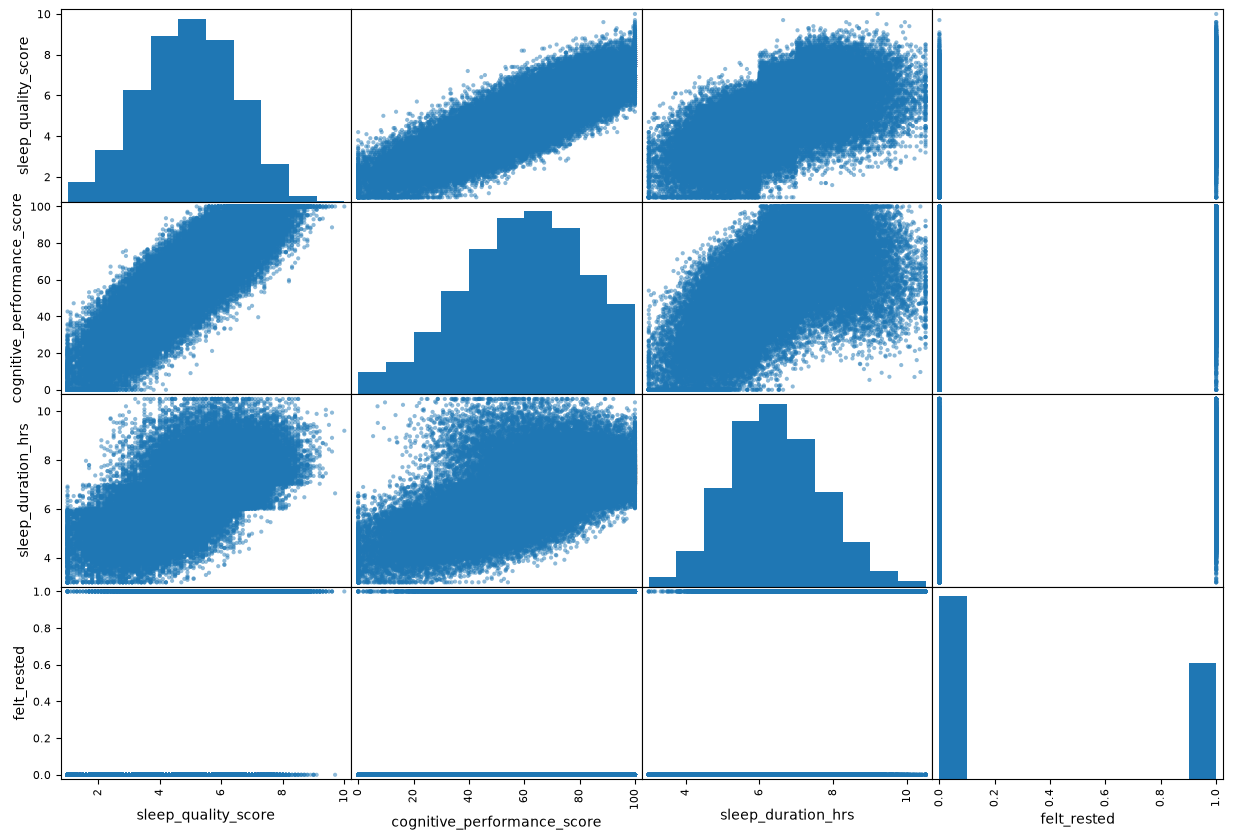

In [27]:
features=["sleep_quality_score","cognitive_performance_score","sleep_duration_hrs","felt_rested"]
scatter_matrix(data[features],figsize=(15,10))
plt.show()

<Axes: xlabel='cognitive_performance_score', ylabel='sleep_quality_score'>

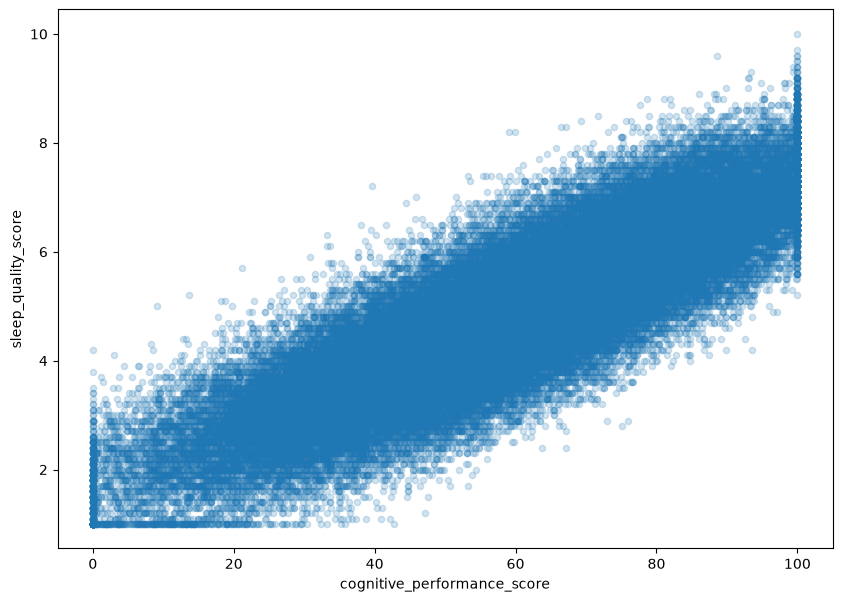

In [28]:
data.plot(
    kind="scatter",
    x="cognitive_performance_score",
    y="sleep_quality_score",
    figsize=(10, 7),
    alpha=0.2
)

In [32]:
data["screen_time_per_sleep_hour"] = ( data["screen_time_before_bed_mins"] / data["sleep_duration_hrs"])
data["work_to_sleep_ratio"] = (data["work_hours_that_day"] / data["sleep_duration_hrs"])
data["caffeine_per_sleep_hour"] = (data["caffeine_mg_before_bed"] / data["sleep_duration_hrs"])
data["rem_to_deep_ratio"] = (data["rem_percentage"] / data["deep_sleep_percentage"])
data["wake_episodes_per_stress"] = (data["wake_episodes_per_night"] / (data["stress_score"] + 1))
data["bmi_per_wake_episode"] = ( data["bmi"] / (data["wake_episodes_per_night"] + 1))
data["alcohol_per_sleep_hour"] = (data["alcohol_units_before_bed"] / data["sleep_duration_hrs"])
data["deep_sleep_duration_hrs"] = (data["sleep_duration_hrs"] *data["deep_sleep_percentage"] / 100)
data["rem_sleep_duration_hrs"] = (data["sleep_duration_hrs"] *data["rem_percentage"] / 100)
data["wake_episodes_per_sleep_hour"] = (data["wake_episodes_per_night"] /data["sleep_duration_hrs"])

In [33]:
corr_matrix=data.corr(numeric_only=True)
corr_matrix["sleep_quality_score"].sort_values(ascending=False)

sleep_quality_score             1.000000
cognitive_performance_score     0.860198
sleep_duration_hrs              0.646306
rem_sleep_duration_hrs          0.634293
deep_sleep_duration_hrs         0.493078
felt_rested                     0.477365
bmi_per_wake_episode            0.300124
rem_percentage                  0.255544
deep_sleep_percentage           0.093855
rem_to_deep_ratio               0.072617
sleep_aid_used                  0.048131
exercise_day                    0.023297
steps_that_day                  0.015689
person_id                       0.000943
weekend_sleep_diff_hrs         -0.003909
nap_duration_mins              -0.019865
room_temperature_celsius       -0.022037
age                            -0.026947
caffeine_mg_before_bed         -0.050719
wake_episodes_per_stress       -0.057221
bmi                            -0.058298
heart_rate_resting_bpm         -0.067729
screen_time_before_bed_mins    -0.081081
alcohol_units_before_bed       -0.081771
caffeine_per_sle